# Install library

In [1]:
#Initial setup
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display

In [2]:
import pandas as pd
import os

In [3]:
import scipy.stats as stats
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from decimal import Decimal, ROUND_HALF_UP
import matplotlib.pyplot as plt
import seaborn as sns

# Import Data

In [4]:
print(os.getcwd())

/home/jovyan/PancreasProject/Aichi_Proteomics


## Omics data

In [5]:
fileDir = "./Data/"
fileName = "pro_data.csv"

path = os.path.join(fileDir, fileName)
temp = pd.read_csv(path)
temp.set_index(temp.columns[0],inplace=True)
temp.index.name = None
display(temp)

pro_data = temp

,OID50001,OID50002,OID50004,OID50005,OID50006,OID50007,OID50008,OID50009,OID50010,OID50011,...,OID51094,OID51095,OID51096,OID51097,OID51098,OID51099,OID51100,OID51101,OID51102,OID51103
PE_R478_001,-0.011714,-0.032043,-0.250458,-0.391125,-0.252621,0.150167,-0.047767,-0.316298,-0.044654,0.516400,...,0.734304,0.110696,0.058819,-0.250565,-0.145040,-0.262231,-0.306965,-0.328111,0.216998,-0.101624
PE_R478_002,0.006932,-0.102609,0.650528,1.724016,0.550598,2.128050,-0.040240,1.335081,0.269637,-0.182468,...,3.043780,0.944960,-0.074905,-0.028470,-0.112292,0.009771,0.605862,1.732763,0.050603,-0.070623
PE_R478_003,-0.060158,0.139603,-0.391076,0.827442,0.564473,0.000000,2.602543,0.168998,-0.149231,0.027239,...,-0.175562,0.927932,0.247506,1.032951,-0.320810,0.012949,0.187431,-0.014972,-0.272747,0.060313
PE_R478_004,0.078249,-0.056538,0.070462,-0.096654,-0.382649,0.026322,0.003985,0.493930,-0.002798,-0.114333,...,-0.603477,-0.421595,0.008789,-0.258851,1.877652,0.111118,0.459926,0.325601,3.782591,-0.063099
PE_R478_005,0.023991,-0.016920,0.378868,0.522751,2.066188,1.183532,0.329253,1.291015,1.488711,1.123200,...,2.440574,0.711782,0.082763,1.664001,1.675150,0.773179,0.788874,0.492789,0.191108,0.228033
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
PE_R478_396,0.099132,0.012226,2.090906,0.937016,0.432914,0.422205,-0.034455,0.301893,-0.417816,0.567447,...,-0.318979,0.567542,-0.176940,-1.468123,0.858104,0.097731,-0.573343,-0.164230,0.004873,-0.195060
PE_R478_397,0.034352,-0.037069,0.652913,-0.084482,0.471556,0.067670,0.048786,1.311366,0.047220,-0.000537,...,0.953380,2.234465,0.233921,-0.020321,3.746860,0.025703,0.553025,0.145132,0.019710,2.857327
PE_R478_398,0.066884,0.005657,0.025657,-0.369096,-0.940943,-0.833491,-0.035938,-0.282643,0.902980,-0.354449,...,0.373973,-0.330692,0.003094,0.760417,-0.094866,-0.042590,0.295296,0.252283,-0.597332,0.102647
PE_R478_399,0.020281,-0.033391,0.115515,0.252649,0.799482,-0.555303,-0.095176,0.147232,-0.232622,0.275772,...,-0.294149,2.978748,-0.111313,-0.910355,0.684876,-0.089939,-0.454858,-0.286652,-0.528971,-0.131158


## Sample data

In [6]:
fileDir = "./Data/"
fileName = "pro_sample.csv"

path = os.path.join(fileDir, fileName)
temp = pd.read_csv(path)
temp.set_index(temp.columns[0],inplace=True)
temp.index.name = None
display(temp)

pro_sample = temp

,progress,sex,fvage,CaCo_Status,icdo3t,icdo3m,smoker,py,drinker,quant_drink_gr,bmi,hx_dm,CA19_9,sIL2R
PE_R478_001,0,1,58,0,NaN,NaN,2,8,1,25,20,0,4.100,134.0
PE_R478_002,0,1,62,0,NaN,NaN,2,10,1,33,23,0,1.999,5500.0
PE_R478_003,0,1,68,0,NaN,NaN,1,24,3,0,22,0,2.700,259.0
PE_R478_004,0,2,70,0,NaN,NaN,3,0,3,0,26,0,3.800,208.0
PE_R478_005,440,1,59,1,C252,81403.0,3,0,3,0,29,0,1200.000,1181.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
PE_R478_396,410,1,63,1,C250,84533.0,1,27,3,0,26,1,1.999,263.0
PE_R478_397,410,2,64,1,C250,85003.0,3,0,1,12,22,0,1.999,257.0
PE_R478_398,0,1,38,0,NaN,NaN,2,13,1,4,29,0,2.100,257.0
PE_R478_399,410,2,47,1,C250,85003.0,3,0,1,2,21,0,16.900,216.0


# Visualization

In [7]:
def plot_distribution_by_sex(variable, xaxis_label):
    tempDF = pro_sample
    tempD = {"All": "k", 1: "tab:red", 2: "tab:blue"}
    tempD2 = {"All": "All", 1: "Male", 2: "Female"}

    # Check distribution
    display(tempDF.groupby("sex")[variable].describe())

    sns.set(style="ticks", context="talk")
    plt.figure(figsize=(4, 3))

    ##Group
    for group in tempD.keys():
        if group == "All":
            tempS = tempDF[variable].dropna()
        else:
            tempS = tempDF[variable].loc[tempDF["sex"] == group].dropna()

        print(f"{tempD2[group]}: skewness = {stats.skew(tempS)}")
        var_label = (
            tempD2[group] + " (" + r"$n$" + " = " + f"{len(tempS):,}" + ")"
        )
        sns.distplot(tempS, label=var_label, color=tempD[group])
        plt.axvline(x=tempS.mean(), **{"linestyle": "--", "color": tempD[group]})

    sns.despine()
    plt.ylabel("Density")
    plt.xlabel(xaxis_label)
    plt.legend(
        bbox_to_anchor=(1, 0.5),
        loc="center left",
        borderaxespad=1,
        labelspacing=0.25,
    )
    plt.show()

def plot_distribution_by_CancerStatus(variable, xaxis_label):
    tempDF = pro_sample
    tempD = {"All": "k", 0: "tab:red", 1: "tab:blue"}
    tempD2 = {"All": "All", 0: "Control", 1: "Cancer"}

    # Check distribution
    display(tempDF.groupby("CaCo_Status")[variable].describe())

    sns.set(style="ticks", context="talk")
    plt.figure(figsize=(4, 3))

    ##Group
    for group in tempD.keys():
        if group == "All":
            tempS = tempDF[variable].dropna()
        else:
            tempS = tempDF[variable].loc[tempDF["CaCo_Status"] == group].dropna()

        print(f"{tempD2[group]}: skewness = {stats.skew(tempS)}")
        var_label = (
            tempD2[group] + " (" + r"$n$" + " = " + f"{len(tempS):,}" + ")"
        )
        sns.distplot(tempS, label=var_label, color=tempD[group])
        plt.axvline(x=tempS.mean(), **{"linestyle": "--", "color": tempD[group]})

    sns.despine()
    plt.ylabel("Density")
    plt.xlabel(xaxis_label)
    plt.legend(
        bbox_to_anchor=(1, 0.5),
        loc="center left",
        borderaxespad=1,
        labelspacing=0.25,
    )
    plt.show()

,count,mean,std,min,25%,50%,75%,max
sex,,,,,,,,
1,227.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0
2,171.0,2.0,0.0,2.0,2.0,2.0,2.0,2.0


All: skewness = 0.28423466515305384
Male: skewness = nan
Female: skewness = nan


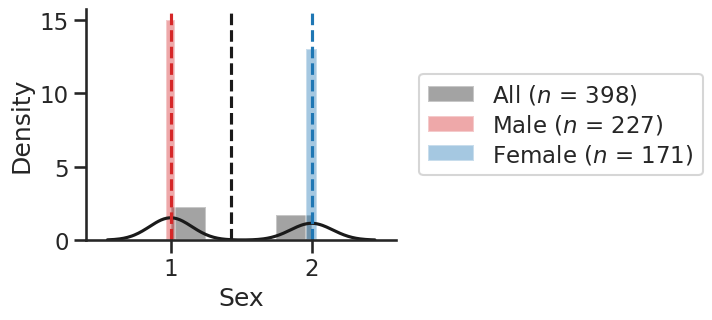

,count,mean,std,min,25%,50%,75%,max
CaCo_Status,,,,,,,,
0,198.0,1.429293,0.496230,1.0,1.0,1.0,2.0,2.0
1,200.0,1.430000,0.496318,1.0,1.0,1.0,2.0,2.0


All: skewness = 0.28423466515305384
Control: skewness = 0.2856994121212249
Cancer: skewness = 0.28278500713637233


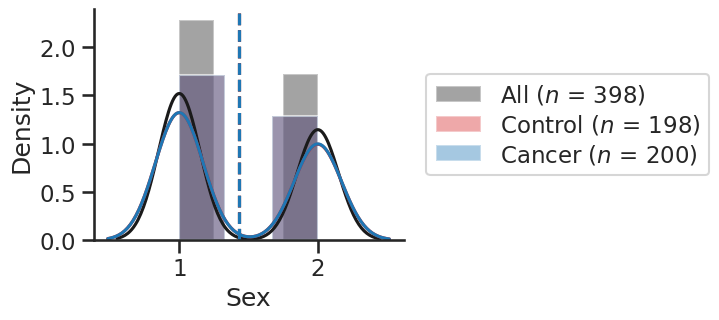

,count,mean,std,min,25%,50%,75%,max
sex,,,,,,,,
1,227.0,0.189427,0.392714,0.0,0.0,0.0,0.0,1.0
2,171.0,0.140351,0.348371,0.0,0.0,0.0,0.0,1.0


All: skewness = 1.7727705508304488
Male: skewness = 1.5851704702068397
Female: skewness = 2.070812716332032


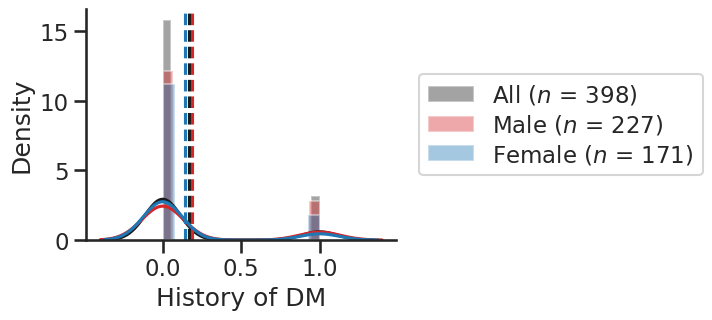

,count,mean,std,min,25%,50%,75%,max
CaCo_Status,,,,,,,,
0,198.0,0.116162,0.321231,0.0,0.0,0.0,0.0,1.0
1,200.0,0.220000,0.415286,0.0,0.0,0.0,0.0,1.0


All: skewness = 1.7727705508304488
Control: skewness = 2.3958556349668667
Cancer: skewness = 1.351852738838749


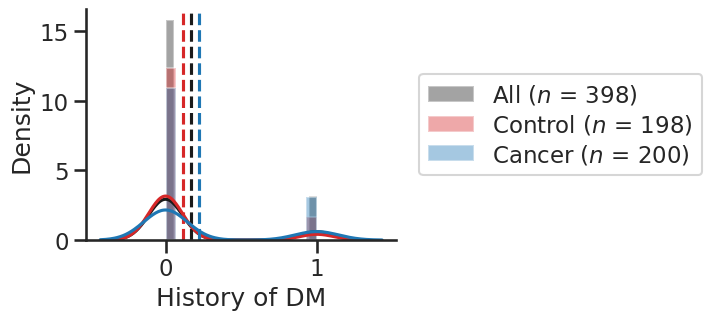

,count,mean,std,min,25%,50%,75%,max
sex,,,,,,,,
1,227.0,0.502203,0.50110,0.0,0.0,1.0,1.0,1.0
2,171.0,0.502924,0.50146,0.0,0.0,1.0,1.0,1.0


All: skewness = -0.010050378152591822
Male: skewness = -0.008810658179869044
Female: skewness = -0.011696106429438495


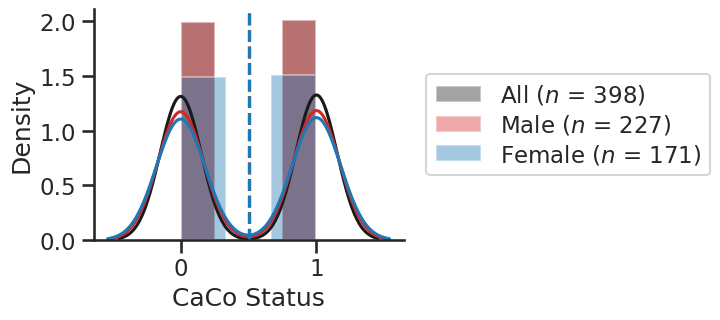

,count,mean,std,min,25%,50%,75%,max
CaCo_Status,,,,,,,,
0,198.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,200.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0


All: skewness = -0.010050378152591822
Control: skewness = nan
Cancer: skewness = nan


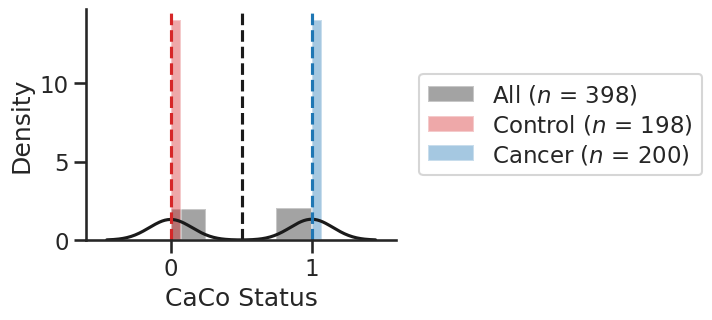

,count,mean,std,min,25%,50%,75%,max
sex,,,,,,,,
1,227.0,210.660793,210.38945,0.0,0.0,400.0,410.0,440.0
2,171.0,211.812865,211.38671,0.0,0.0,400.0,420.0,440.0


All: skewness = -0.004565672135269505
Male: skewness = -0.0033247405728806644
Female: skewness = -0.006267984039470816


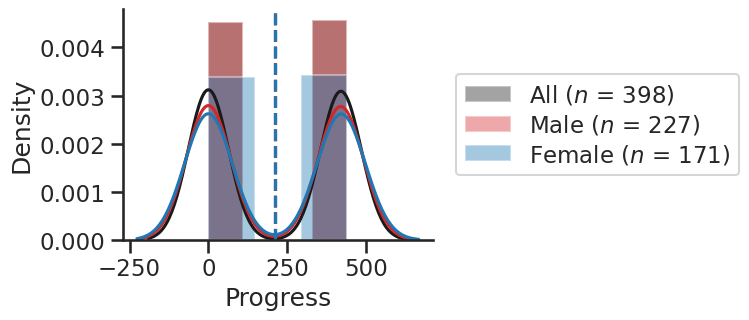

,count,mean,std,min,25%,50%,75%,max
CaCo_Status,,,,,,,,
0,198.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0
1,200.0,420.2,12.679267,400.0,410.0,410.0,430.0,440.0


All: skewness = -0.004565672135269505
Control: skewness = nan
Cancer: skewness = 0.3331601990465104


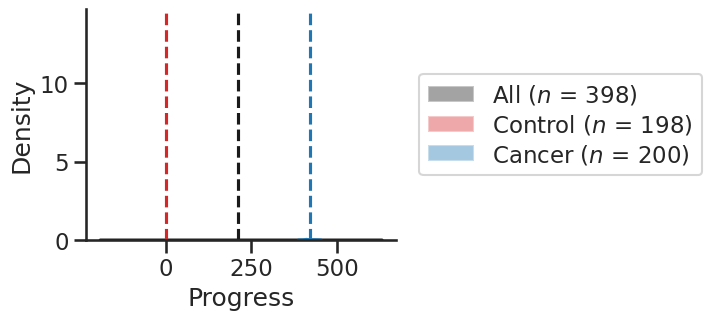

,count,mean,std,min,25%,50%,75%,max
sex,,,,,,,,
1,227.0,63.048458,11.426655,17.0,56.0,64.0,71.0,88.0
2,171.0,59.573099,12.583331,16.0,54.0,61.0,69.0,79.0


All: skewness = -0.9296003685506767
Male: skewness = -0.7653761382096408
Female: skewness = -1.0608123123933806


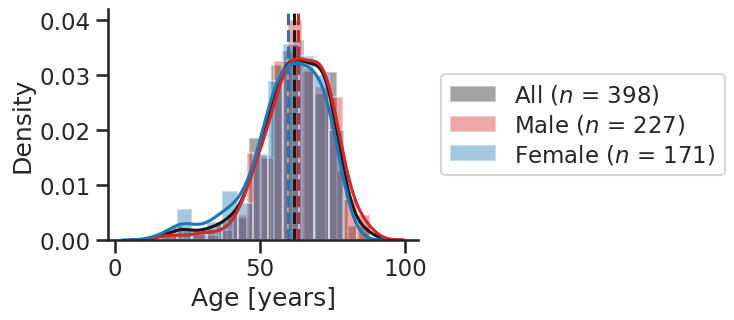

,count,mean,std,min,25%,50%,75%,max
CaCo_Status,,,,,,,,
0,198.0,60.974747,12.296026,21.0,54.0,62.0,71.0,88.0
1,200.0,62.130000,11.795285,16.0,56.0,64.0,70.0,86.0


All: skewness = -0.9296003685506767
Control: skewness = -0.7497875479254549
Cancer: skewness = -1.12410619822111


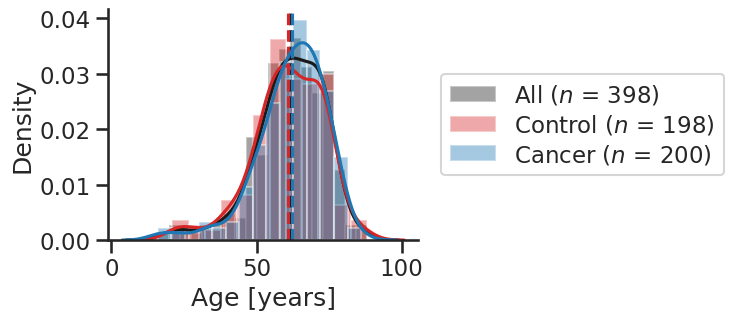

,count,mean,std,min,25%,50%,75%,max
sex,,,,,,,,
1,227.0,22.991189,26.086648,0.0,0.0,18.0,37.0,168.0
2,171.0,2.461988,7.273038,0.0,0.0,0.0,0.0,45.0


All: skewness = 2.4354418740580477
Male: skewness = 1.8435445388421499
Female: skewness = 3.438650381268009


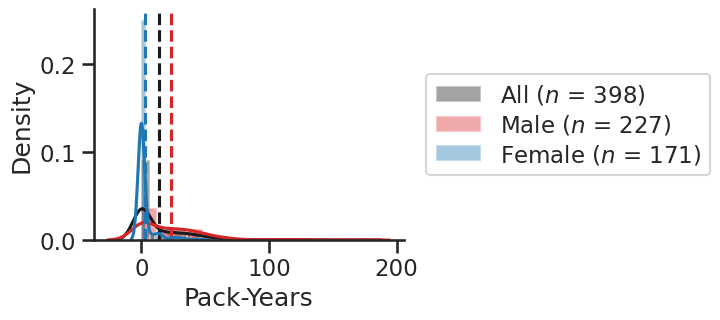

,count,mean,std,min,25%,50%,75%,max
CaCo_Status,,,,,,,,
0,198.0,13.964646,25.410813,0.0,0.0,0.0,20.0,168.0
1,200.0,14.375000,19.628570,0.0,0.0,0.0,26.0,99.0


All: skewness = 2.4354418740580477
Control: skewness = 2.8776865824785154
Cancer: skewness = 1.327462082815138


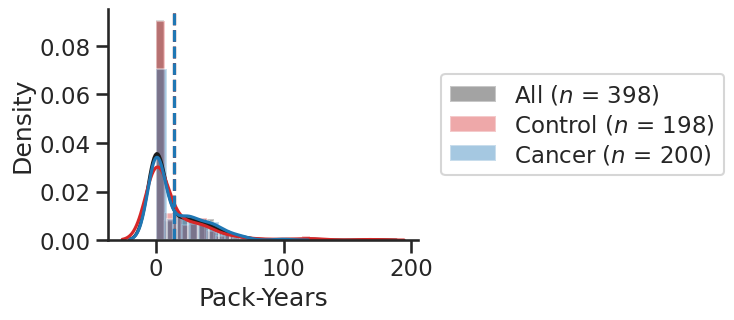

,count,mean,std,min,25%,50%,75%,max
sex,,,,,,,,
1,227.0,20.696035,29.837912,0.0,0.0,10.0,30.0,215.0
2,171.0,4.204678,8.967207,0.0,0.0,0.0,3.0,41.0


All: skewness = 3.6232569086915936
Male: skewness = 2.9036377938105185
Female: skewness = 2.5987758587614453


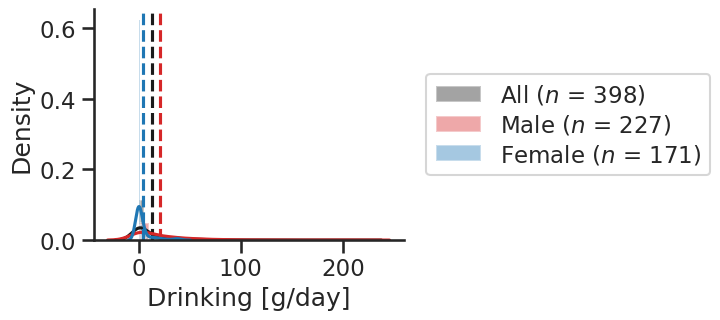

,count,mean,std,min,25%,50%,75%,max
CaCo_Status,,,,,,,,
0,198.0,15.459596,28.897963,0.0,0.0,3.0,20.75,215.0
1,200.0,11.780000,19.483574,0.0,0.0,0.5,18.00,113.0


All: skewness = 3.6232569086915936
Control: skewness = 3.7839258548341776
Cancer: skewness = 2.1113821485304087


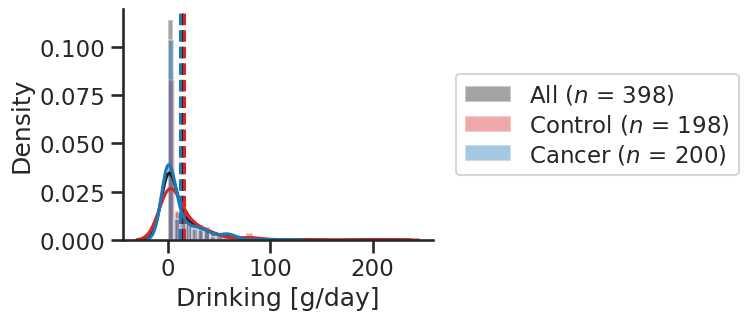

,count,mean,std,min,25%,50%,75%,max
sex,,,,,,,,
1,227.0,23.202643,3.344973,15.0,21.0,23.0,25.0,34.0
2,171.0,21.713450,3.495341,15.0,19.0,21.0,24.0,34.0


All: skewness = 0.7641601927151188
Male: skewness = 0.6569957318566575
Female: skewness = 1.0726758310351188


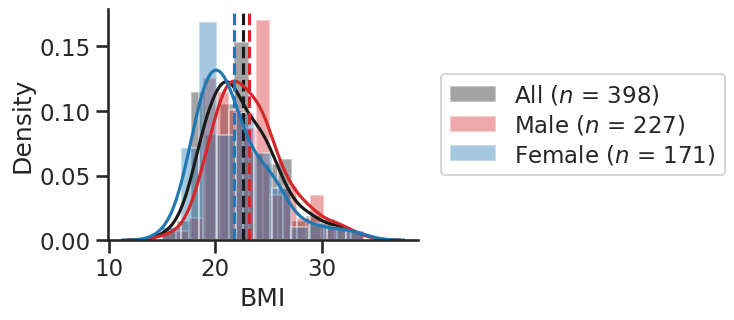

,count,mean,std,min,25%,50%,75%,max
CaCo_Status,,,,,,,,
0,198.0,22.772727,3.502554,15.0,20.0,22.0,25.0,33.0
1,200.0,22.355000,3.463953,15.0,20.0,22.0,24.0,34.0


All: skewness = 0.7641601927151188
Control: skewness = 0.6505763599012122
Cancer: skewness = 0.8846791898037646


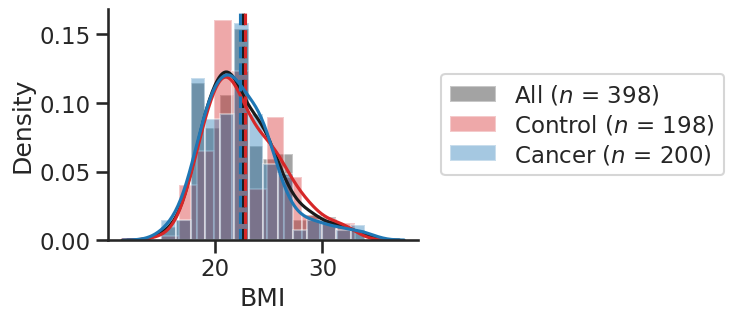

In [8]:
cols_dict = {
    "sex": "Sex",
    "hx_dm": "History of DM",
    "CaCo_Status": "CaCo Status",
    "progress": "Progress",
    "fvage": "Age [years]",
    "py": "Pack-Years",
    "quant_drink_gr": "Drinking [g/day]",
    "bmi": "BMI",
}

# 2. ループで順に実行
for col, label in cols_dict.items():
    plot_distribution_by_sex(col, label)
    plot_distribution_by_CancerStatus(col, label)